# 03 · Why do the evaluators disagree?

**Reader goal:** distinguish native score differences, rank association,
segmentation differences and claim-level judgement, without treating the highest
or lowest score as evidence of evaluator quality.

**Reading route:** common cohort and definitions → paired score differences →
ranking → native claim counts → disagreements in both directions → validation needs.

BACE, RAGChecker and RAGAS evaluate the same generated text and visible evidence,
but construct different claim inventories. Their native rates therefore have
different denominators. The shared judge deployment also means that agreement
between them is not independent confirmation of correctness.

**How to read this notebook.** Each figure begins with a specific question. Its
caption explains the encodings and analysis scope; the following paragraphs
describe the observed pattern, its interpretation, and the remaining limits.
For multi-panel figures, read the individual panels and then their joint meaning.
“Middle half” means the 25th–75th percentiles. In an empirical cumulative
distribution (ECDF), the vertical coordinate is the proportion at or below the
horizontal value; a steep section marks a concentration of observations.
All of this text remains visible when code is hidden.

In [1]:
from pathlib import Path
import sys
analysis_dir = Path.cwd()
if not (analysis_dir / 'analysis_data.py').exists():
    analysis_dir = analysis_dir / 'BACE' / 'analysis'
assert (analysis_dir / 'analysis_data.py').exists(), 'Run from the project root or analysis directory.'
sys.path.insert(0, str(analysis_dir))
sys.dont_write_bytecode = True
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from analysis_data import (load_snapshot, company_bootstrap, case_material, read, rows,
                           save_json, sha, HERE, BACE, ROOT, OUT, CACHE, SEED, METHODS, TASKS, LABELS)
from figure_style import (canvas, save_figure, quote_figure, ecdf, note,
                          BLUE, GREEN, ORANGE, GREY, INK, CMAP,
                          METHOD_COLORS, TYPE_COLORS, LABEL_NAMES, LABEL_COLORS)
tables = load_snapshot()
metrics = tables['metrics']
common = metrics.loc[metrics.bace_complete & metrics.ragchecker_complete & metrics.ragas_complete].copy()
bace = metrics.loc[metrics.bace_complete].copy()
claims = tables['claims']
sample = read(CACHE / 'sample.json')
execution = read(CACHE / 'execution.json')
note(f"**Snapshot:** {len(metrics):,} planned disclosures from {metrics.company_id.nunique()} companies; "
     f"{len(bace):,} complete BACE results and {len(common):,} common completed cases. "
     f"Run status: `{execution['status']}`. All results are automated; no human accuracy benchmark is supplied.")

**Snapshot:** 1,800 planned disclosures from 30 companies; 1,798 complete BACE results and 1,798 common completed cases. Run status: `incomplete`. All results are automated; no human accuracy benchmark is supplied.

**Statistical scope.** The primary unit of presentation is a disclosure (company × year × task).
Repeated disclosures and extracted claims from the same company are dependent.
Where shown, 95% percentile intervals use 2,000 company-cluster bootstrap draws
(seed 20260921), resampling companies with replacement and retaining all their
observed disclosures. These are empirical, unweighted sample summaries, not
design-adjusted population estimates. They do not capture generation/judge
randomness or uncertainty due to the two missing BACE results. Subgroup comparisons
are descriptive; no hypothesis tests, significance stars or causal claims are made.

## 1. How do the native scores differ on the same disclosures?

All paired comparisons below use the common completed cohort. External-only
cases remain in the execution inventory and their complete-cohort summaries are
reported explicitly rather than silently mixed into paired comparisons.

<a id="reading-03_native_comparison"></a>

**Figure question · 03 native comparison.** On the identical completed disclosures, how far apart are native score distributions and paired means?

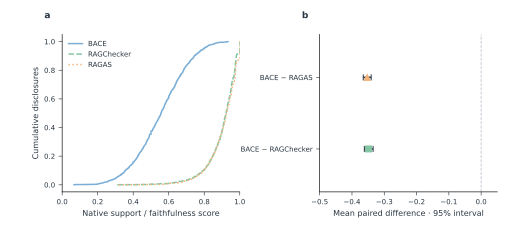

**Read the figure:** panel a gives each common disclosure equal weight; panel b first subtracts scores within the same disclosure, then bootstraps company clusters. The intervals describe paired native score gaps, not differences in evaluator accuracy.

[PDF](outputs/figures/03/03_native_comparison.pdf) · [SVG](outputs/figures/03/03_native_comparison.svg) · [PNG](outputs/figures/03/03_native_comparison.png) · [Source data: scores](outputs/figures/03/03_native_comparison__scores.csv) · [Source data: cohort_summary](outputs/figures/03/03_native_comparison__cohort_summary.csv) · [Source data: paired_differences](outputs/figures/03/03_native_comparison__paired_differences.csv)

**Pattern and evidence.** Panel a rises mainly in the middle of the score axis for BACE and near its upper end for both comparators: BACE: median 55.6%, middle half 45.2%–65.9%, 8/1,798 at or above 0.90 and 0 exactly 1.00; RAGChecker: median 92.3%, middle half 86.5%–96.4%, 1,139/1,798 at or above 0.90 and 155 exactly 1.00; RAGAS: median 92.5%, middle half 86.7%–97.3%, 1,146/1,798 at or above 0.90 and 233 exactly 1.00. The two comparator curves overlap extensively, including their central ranges. Panel b puts both paired mean differences well left of zero: BACE − RAGChecker: -34.9 percentage points (95% company-cluster interval -36.2 to -33.5); BACE − RAGAS: -35.3 percentage points (95% company-cluster interval -36.5 to -34.1).

**Interpretation.** The broad curve separation and the negative paired differences jointly show that the score gap is not just an artefact of comparing different case cohorts. High-end concentration also gives the comparators less room to distinguish already high-scoring disclosures. Similar comparator distributions do not imply matching judgements on each case.

**Limits and alternative readings.** An ECDF higher at a given threshold means more observations at or below that score, not better performance. The denominator is each pipeline’s own claim inventory. A lower native score cannot identify stricter judgement as the sole mechanism or prove greater accuracy. Intervals resample 30 company clusters and do not measure judge randomness.

**BACE, common cohort:** mean 55.4% (95% interval 53.9%–56.8%; 1,798 disclosures, 30 companies).

**RAGChecker, common cohort:** mean 90.2% (95% interval 89.5%–90.9%; 1,798 disclosures, 30 companies).

**RAGChecker, all available cohort:** mean 90.2% (95% interval 89.5%–90.9%; 1,800 disclosures, 30 companies).

**RAGAS, common cohort:** mean 90.7% (95% interval 90.0%–91.3%; 1,798 disclosures, 30 companies).

**RAGAS, all available cohort:** mean 90.7% (95% interval 90.0%–91.3%; 1,800 disclosures, 30 companies).

In [2]:
summary_rows=[]
for method,column in METHODS.items():
    summary_rows.append({'method':method,'cohort':'Common',**company_bootstrap(common,column)})
    if method!='BACE':
        summary_rows.append({'method':method,'cohort':'All available',**company_bootstrap(metrics.dropna(subset=[column]),column)})
summary=pd.DataFrame(summary_rows)
fig,axs=canvas(height=87,cols=2,left=.12,right=.96,bottom=.22,top=.86,wspace=.45)
for method,column in METHODS.items():
    ecdf(axs[0],common[column],METHOD_COLORS[method],method,{'BACE':'-','RAGChecker':'--','RAGAS':':'}[method])
axs[0].set_xlim(0,1);axs[0].set_xlabel('Native support / faithfulness score');axs[0].set_ylabel('Cumulative disclosures');axs[0].legend(loc='upper left')
differences=[]
for j,other in enumerate(['RAGChecker','RAGAS']):
    column='difference_'+other
    common[column]=common[METHODS['BACE']]-common[METHODS[other]]
    stats=company_bootstrap(common,column);differences.append({'contrast':'BACE − '+other,**stats})
    axs[1].errorbar(stats['mean'],j,xerr=[[stats['mean']-stats['low']],[stats['high']-stats['mean']]],fmt=['s','^'][j],color=METHOD_COLORS[other],ecolor=INK,capsize=3)
axs[1].axvline(0,color=GREY,lw=.8,ls='--');axs[1].set_yticks([0,1],['BACE − RAGChecker','BACE − RAGAS'],fontsize=7)
axs[1].set_ylim(-.6,1.6);axs[1].set_xlim(-.5,.05);axs[1].set_xlabel('Mean paired difference · 95% interval')
save_figure(fig,'03_native_comparison',{'scores':common[['generation_case_id','company_id',*METHODS.values()]],'cohort_summary':summary,'paired_differences':pd.DataFrame(differences)},
    '**Read the figure:** panel a gives each common disclosure equal weight; panel b first subtracts scores within the same disclosure, then bootstraps company clusters. '
    'The intervals describe paired native score gaps, not differences in evaluator accuracy.')
for r in summary.itertuples():
    note(f"**{r.method}, {r.cohort.lower()} cohort:** mean {r.mean:.1%} (95% interval {r.low:.1%}–{r.high:.1%}; {r.disclosures:,} disclosures, {r.companies} companies).")

## 2. Do high-scoring disclosures stay high across evaluators?

Score-level agreement and rank association are distinct. A shared ordering can
coexist with a large systematic difference in score level. Every point below is
a common disclosure; overplotting is handled with transparency, not sampling.

<a id="reading-03_rank_agreement"></a>

**Figure question · 03 rank agreement.** Does the distributional gap also mean that evaluators order the same disclosures differently?

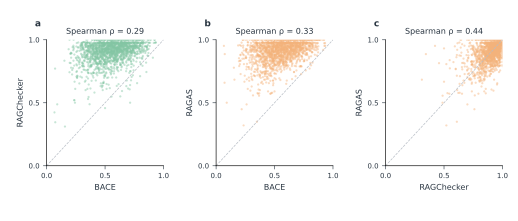

**Read the figure:** the dashed line is equal native scores, not a fitted regression. Spearman coefficients are descriptive and include ties. No p-values are reported because disclosures are clustered and the purpose is descriptive. Shared judge deployment limits independence.

[PDF](outputs/figures/03/03_rank_agreement.pdf) · [SVG](outputs/figures/03/03_rank_agreement.svg) · [PNG](outputs/figures/03/03_rank_agreement.png) · [Source data: scores](outputs/figures/03/03_rank_agreement__scores.csv) · [Source data: rank_associations](outputs/figures/03/03_rank_agreement__rank_associations.csv)

**Pattern and evidence.** Panel a (BACE versus RAGChecker): ρ=0.289; 1,778 points above the equality line, 19 below and 1 tied; 1.5% differ by at most 0.05. Panel b (BACE versus RAGAS): ρ=0.328; 1,792 points above the equality line, 4 below and 2 tied; 0.9% differ by at most 0.05. Panel c (RAGChecker versus RAGAS): ρ=0.445; 879 points above the equality line, 850 below and 69 tied; 55.4% differ by at most 0.05. In panels a and b the cloud lies overwhelmingly above the diagonal, with wide horizontal spread under high comparator scores. Panel c has points on both sides, with 867/1798 in the upper-right square where both scores are at least 0.90.

**Interpretation.** All three rank associations are positive, but the dispersion shows that agreement is partial. Panels a and b combine a large level offset with only modest shared ordering; panel c has closer score levels and stronger rank association, yet substantial case-level disagreement remains. The ceiling creates ties and crowded top-edge bands.

**Limits and alternative readings.** The diagonal is equality, not a fitted trend, and darkness reflects overplotting as well as density. Each panel retains all common disclosures, which are dependent within companies. Descriptive correlations and shared judge deployment cannot establish an independent accuracy ranking.

In [3]:
from scipy.stats import spearmanr
pairs=[('BACE','RAGChecker'),('BACE','RAGAS'),('RAGChecker','RAGAS')]
rank_rows=[]
fig,axs=canvas(height=78,cols=3,left=.09,right=.97,bottom=.25,top=.82,wspace=.45)
for ax,(a,b) in zip(axs,pairs):
    x=common[METHODS[a]];y=common[METHODS[b]]
    ax.scatter(x,y,s=5,alpha=.45,color=METHOD_COLORS[b],edgecolors='none',rasterized=True)
    ax.plot([0,1],[0,1],color=GREY,ls='--',lw=.7);ax.set_xlim(0,1);ax.set_ylim(0,1)
    ax.set_xticks([0,.5,1]);ax.set_yticks([0,.5,1]);ax.set_xlabel(a);ax.set_ylabel(b)
    rho=float(spearmanr(x,y).statistic);rank_rows.append({'method_a':a,'method_b':b,'spearman_rho':rho,'disclosures':len(common),'companies':common.company_id.nunique()})
    ax.set_title(f'Spearman ρ = {rho:.2f}',fontsize=8)
save_figure(fig,'03_rank_agreement',{'scores':common[['generation_case_id','company_id',*METHODS.values()]],'rank_associations':pd.DataFrame(rank_rows)},
    '**Read the figure:** the dashed line is equal native scores, not a fitted regression. Spearman coefficients are descriptive and include ties. '
    'No p-values are reported because disclosures are clustered and the purpose is descriptive. Shared judge deployment limits independence.')

## 3. How much does the claim inventory differ?

Before attributing a score gap to stricter judgement, inspect the extracted claim
counts. Different segmentation, omitted content and non-disclosure treatment can
change both numerator and denominator. A count difference alone cannot quantify
how much of a score gap it caused.

<a id="reading-03_claim_inventories"></a>

**Figure question · 03 claim inventories.** Could different claim segmentation help explain why native rates disagree on the same text?

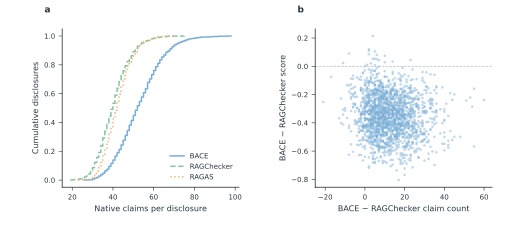

**Read the figure:** panel a includes every native claim count; panel b compares within-disclosure count and score differences. No causal decomposition is implied. DC totals and comparator claim totals are different inventories, not a shared set of propositions.

[PDF](outputs/figures/03/03_claim_inventories.pdf) · [SVG](outputs/figures/03/03_claim_inventories.svg) · [PNG](outputs/figures/03/03_claim_inventories.png) · [Source data: data](outputs/figures/03/03_claim_inventories__data.csv)

**Pattern and evidence.** Panel a places BACE’s central claim-count range to the right: BACE median 52, middle half 45–60; RAGChecker median 40, middle half 35–45; RAGAS median 42, middle half 37–46. In panel b, the count difference has median 11 (middle half 5–19; range -21 to 60). 1,614/1,798 points combine more BACE claims with a lower BACE score. The count-gap/score-gap rank association is weakly negative (ρ=-0.104); the cloud is not a tight descending relation.

**Interpretation.** BACE usually produces a larger native inventory, so the score denominators differ systematically. The loose scatter means that the number of additional claims alone is an inadequate explanation of each score gap. Content selection, splits and merges, and support decisions all remain relevant.

**Limits and alternative readings.** The two axes are outcomes of the same pipelines, not independently manipulated variables. A negative association cannot assign a causal fraction of the score gap to segmentation. More claims do not necessarily mean more complete or more accurate extraction; one proposition can be split differently.

In [4]:
claim_columns={'BACE':'bace_dc_count','RAGChecker':'ragchecker_claim_count','RAGAS':'ragas_claim_count'}
fig,axs=canvas(height=85,cols=2,left=.12,right=.95,bottom=.22,top=.88,wspace=.43)
for method,column in claim_columns.items():
    ecdf(axs[0],common[column],METHOD_COLORS[method],method,{'BACE':'-','RAGChecker':'--','RAGAS':':'}[method])
axs[0].set_xlabel('Native claims per disclosure');axs[0].set_ylabel('Cumulative disclosures');axs[0].legend(loc='lower right')
claim_delta=common.bace_dc_count-common.ragchecker_claim_count
score_delta=common.bace_support_rate_all_dc-common.ragchecker_faithfulness
axs[1].scatter(claim_delta,score_delta,s=7,color=BLUE,alpha=.45,edgecolors='none',rasterized=True)
axs[1].axhline(0,color=GREY,lw=.7,ls='--');axs[1].set_xlabel('BACE − RAGChecker claim count');axs[1].set_ylabel('BACE − RAGChecker score')
save_figure(fig,'03_claim_inventories',common[['generation_case_id','company_id',*claim_columns.values(),*METHODS.values()]],
    '**Read the figure:** panel a includes every native claim count; panel b compares within-disclosure count and score differences. No causal decomposition is implied. '
    'DC totals and comparator claim totals are different inventories, not a shared set of propositions.')

## 4. Where do disagreements concentrate by task?

A paired gap can vary by task. This chart retains the fixed task order and both
comparators; it does not select only tasks with the largest gap.

<a id="reading-03_task_disagreement"></a>

**Figure question · 03 task disagreement.** Is the global score offset spread across all tasks, and do both comparators show the same task profile?

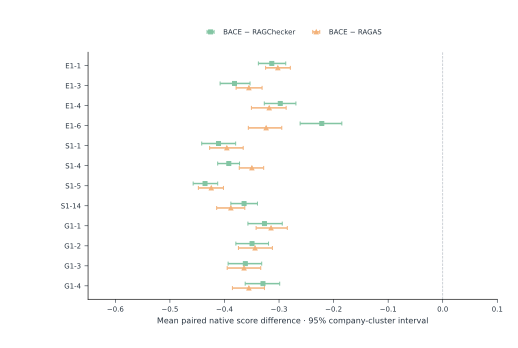

**Read the figure:** each point is a within-task paired macro difference, with the same 2,000-draw company bootstrap procedure. All task rows are shown, including reduced denominators from the incomplete BACE cases. No multiple-comparison significance claim is made.

[PDF](outputs/figures/03/03_task_disagreement.pdf) · [SVG](outputs/figures/03/03_task_disagreement.svg) · [PNG](outputs/figures/03/03_task_disagreement.png) · [Source data: data](outputs/figures/03/03_task_disagreement__data.csv)

**Pattern and evidence.** All 24 task-by-comparator mean gaps are negative: against RAGChecker, from -43.6 points (S1-5) to -22.2 (E1-6); against RAGAS, from -42.4 points (S1-5) to -30.2 (E1-1). All displayed upper interval bounds also remain below zero. The largest separation between the two comparator gaps occurs at E1-6: -22.2 versus -32.4 points, a 10.2-point difference.

**Interpretation.** The overall offset is distributed across tasks rather than arising from one isolated row. The different gap sizes, especially for E1-6, show that similar global comparator means can conceal task-specific differences in segmentation or evidence judgement.

**Limits and alternative readings.** The intervals describe within-task paired gaps under company resampling. Their position is not an evaluator-accuracy test, and no multiplicity-adjusted comparison of tasks is claimed. The same companies appear in all rows; task evidence, generated claims and native inventories all vary together.

In [5]:
gaps=[]
for task in TASKS:
    view=common[common.task==task].copy()
    for other in ['RAGChecker','RAGAS']:
        view['gap']=view.bace_support_rate_all_dc-view[METHODS[other]]
        gaps.append({'task':task,'comparison':other,**company_bootstrap(view,'gap')})
gaps=pd.DataFrame(gaps)
fig,(ax,)=canvas(height=123,left=.17,right=.96,bottom=.14,top=.85)
for j,(other,marker) in enumerate([('RAGChecker','s'),('RAGAS','^')]):
    view=gaps[gaps.comparison==other].set_index('task').loc[TASKS]
    ax.errorbar(view['mean'],np.arange(len(TASKS))+(j-.5)*.22,xerr=[view['mean']-view.low,view.high-view['mean']],fmt=marker,color=METHOD_COLORS[other],ecolor=METHOD_COLORS[other],capsize=2,label='BACE − '+other,markersize=4)
ax.axvline(0,color=GREY,lw=.7,ls='--');ax.set_yticks(range(len(TASKS)),TASKS);ax.invert_yaxis();ax.set_xlim(-.65,.1)
ax.set_xlabel('Mean paired native score difference · 95% company-cluster interval');ax.legend(loc='lower center',bbox_to_anchor=(.5,1.04),ncols=2)
save_figure(fig,'03_task_disagreement',gaps,
    '**Read the figure:** each point is a within-task paired macro difference, with the same 2,000-draw company bootstrap procedure. '
    'All task rows are shown, including reduced denominators from the incomplete BACE cases. No multiple-comparison significance claim is made.')

## 5. Can we compare individual claims without pretending inventories match?

The following audit matches only **identical text after Unicode case-folding and
whitespace normalisation within the same case**. RAGChecker triples are joined
with spaces; no semantic matching or punctuation removal is performed. Ambiguous
repeated keys are excluded from this narrow alignment audit and counted.

This deliberately restricted overlap cannot estimate global evaluator accuracy
or agreement. Unmatched claims are not disagreements: they may be paraphrases,
splits, merges or omissions.

<a id="reading-03_alignment_coverage"></a>

**Figure question · 03 alignment coverage.** After seeing different native inventories, how much can a strict literal-text match actually align?

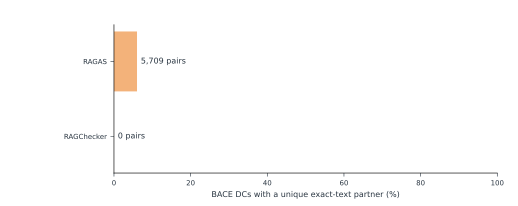

**Read the figure:** bars show alignment coverage, not support or agreement. Ambiguous key counts and total native inventories are exported. **Boundary:** selection into exact-text overlap is highly non-random; matched judgement agreement cannot be extrapolated to all claims.

[PDF](outputs/figures/03/03_alignment_coverage.pdf) · [SVG](outputs/figures/03/03_alignment_coverage.svg) · [PNG](outputs/figures/03/03_alignment_coverage.png) · [Source data: data](outputs/figures/03/03_alignment_coverage__data.csv)

**Pattern and evidence.** One bar is zero: RAGChecker has 0 unique exact-text partners. RAGAS has 5,709/94,955, covering 6.0% of BACE DCs. Within that restricted RAGAS overlap, 3,669 pairs (64.3%) share the binary verdict. 6 ambiguous RAGAS rows are excluded; no BACE rows have ambiguous keys.

**Interpretation.** The near-empty coverage exposes the limits of literal alignment. RAGChecker represents claims as joined triples, whereas BACE uses sentences, so semantically related propositions can fail the exact-string rule. The nonzero RAGAS overlap supplies a narrow inspectable subset, not a common denominator for the three full evaluations.

**Limits and alternative readings.** Zero literal matches is not zero semantic overlap, and an unmatched claim is not a verdict disagreement. Matching text is a highly selected subset; its binary agreement cannot be extrapolated to unmatched claims or interpreted as accuracy. All unmatched claims remain in the native-score analyses.

**ragchecker:** 0 unique exact-text pairs; 0 have matching binary verdicts. Ambiguous rows excluded: BACE 0, comparator 0. Unmatched rows remain in all native score analyses.

**ragas:** 5,709 unique exact-text pairs; 3,669 have matching binary verdicts. Ambiguous rows excluded: BACE 0, comparator 6. Unmatched rows remain in all native score analyses.

In [6]:
normalise=lambda text:' '.join(str(text).casefold().split())
left=claims[claims.generation_case_id.isin(common.generation_case_id)].copy()
left['key']=left.dc_text.map(normalise);left['supported']=left.label.isin(['direct','inferred'])
ext=tables['external_claims'];alignment=[];matched_tables=[]
for framework in ['ragchecker','ragas']:
    right=ext[(ext.framework==framework)&ext.generation_case_id.isin(common.generation_case_id)].copy()
    right['key']=right.claim_text.map(normalise)
    keys=['generation_case_id','key']
    lu=left[~left.duplicated(keys,keep=False)];ru=right[~right.duplicated(keys,keep=False)]
    match=lu.merge(ru,on=keys,suffixes=('_bace','_external'),validate='one_to_one')
    match['agreement']=match.supported_bace==match.supported_external
    alignment.append({'framework':framework,'bace_claims':len(left),'external_claims':len(right),'matched_pairs':len(match),
                      'agreements':int(match.agreement.sum()),'bace_ambiguous_rows':len(left)-len(lu),'external_ambiguous_rows':len(right)-len(ru)})
    matched_tables.append(match)
alignment=pd.DataFrame(alignment)
fig,(ax,)=canvas(height=73,left=.22)
coverage=100*alignment.matched_pairs/alignment.bace_claims
ax.barh(['RAGChecker','RAGAS'],coverage,color=[GREEN,ORANGE]);ax.set_xlim(0,100);ax.set_xlabel('BACE DCs with a unique exact-text partner (%)')
for i,r in enumerate(alignment.itertuples()):ax.text(coverage.iloc[i]+1,i,f'{r.matched_pairs:,} pairs',va='center',fontsize=8)
save_figure(fig,'03_alignment_coverage',alignment,
    '**Read the figure:** bars show alignment coverage, not support or agreement. Ambiguous key counts and total native inventories are exported. '
    '**Boundary:** selection into exact-text overlap is highly non-random; matched judgement agreement cannot be extrapolated to all claims.')
for r in alignment.itertuples():
    note(f"**{r.framework}:** {r.matched_pairs:,} unique exact-text pairs; {r.agreements:,} have matching binary verdicts. "
         f"Ambiguous rows excluded: BACE {r.bace_ambiguous_rows:,}, comparator {r.external_ambiguous_rows:,}. Unmatched rows remain in all native score analyses.")
for framework,matched in zip(['ragchecker','ragas'],matched_tables):
    matched.to_csv(OUT/f'{framework}_exact_text_pairs.csv',index=False)

## 6. What do disagreements in both directions look like?

**Case selection:** among common cases, select the minimum and maximum
BACE-minus-RAGChecker score gaps (ties broken by case ID). These are deliberately
extreme illustrations, not representative estimates. Show all three native
scores and claim inventories; retain the full generated text and both comparison
outputs in the exported case bundle.

<a id="reading-03_case_lower"></a>

**Figure question · 03 case lower.** What does the most negative BACE-minus-RAGChecker case look like beneath its aggregate scores?

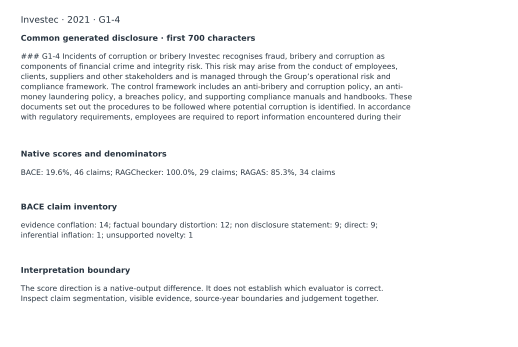

**Observed:** BACE minus RAGChecker = -0.804. This is an extreme case selected to explain a disagreement direction; it is not an accuracy example. [Full case](outputs/examples/03_bace_lower_than_ragchecker.json).

[PDF](outputs/figures/03/03_case_lower.pdf) · [SVG](outputs/figures/03/03_case_lower.svg) · [PNG](outputs/figures/03/03_case_lower.png) · [Source data: data](outputs/figures/03/03_case_lower__data.csv)

**Pattern and evidence.** Investec 2021 G1-4 has a -80.4-point gap: BACE supports 9/46 DCs (19.6%), RAGChecker supports 29/29 native claims (100.0%), and RAGAS supports 29/34 (85.3%). The BACE inventory includes 14 conflation, 12 boundary and 9 non-disclosure DCs, plus one inflation and one novelty DC. Thus the gap combines a larger inventory with a very different allocation of unsupported labels.

**Interpretation.** The opening passage sounds coherent and describes controls, but prose fluency alone does not settle its source support. The inventory points to temporal and relational reading as useful inspection targets. The supplier example below then checks one specific source-coverage disagreement within this same case.

**Limits and alternative readings.** This is the minimum paired gap selected from the common cohort, so its magnitude is intentionally extreme. The displayed opening is only the first 700 characters and cannot explain every verdict. Neither the perfect comparator score nor the low BACE score is a human accuracy label.

<a id="reading-03_case_higher"></a>

**Figure question · 03 case higher.** Can the score ordering reverse, and what evidence structure appears in the most positive case?

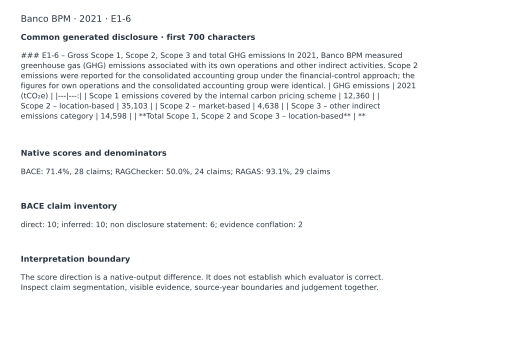

**Observed:** BACE minus RAGChecker = +0.214. This is an extreme case selected to explain a disagreement direction; it is not an accuracy example. [Full case](outputs/examples/03_bace_higher_than_ragchecker.json).

[PDF](outputs/figures/03/03_case_higher.pdf) · [SVG](outputs/figures/03/03_case_higher.svg) · [PNG](outputs/figures/03/03_case_higher.png) · [Source data: data](outputs/figures/03/03_case_higher__data.csv)

**Pattern and evidence.** Banco BPM 2021 E1-6 has a 21.4-point BACE-minus-RAGChecker gap. BACE supports 20/28 DCs (71.4%): ten direct and ten inferred. RAGChecker supports 12/24 claims (50.0%), while RAGAS supports 27/29 (93.1%). The eight unsupported BACE DCs comprise six non-disclosure statements and two conflation labels. The generated opening contains several emissions quantities and an equality relation.

**Interpretation.** The reversal rules out a universal case-by-case ordering in which BACE always scores lowest. The sizeable inferred component makes cross-card numerical relationships worth inspecting; the four-value equality example below provides one such traceable path. RAGAS still scores higher, so this case does not reverse every pairwise ordering.

**Limits and alternative readings.** This is the maximum BACE-minus-RAGChecker gap, not a representative emissions task. Different inventories prevent attributing the entire gap to one equality claim or to inference alone. Numerical consistency among extracted cards is not external verification of the underlying emissions data.

In [7]:
common['gap_rc']=common.bace_support_rate_all_dc-common.ragchecker_faithfulness
ordered=common.sort_values(['gap_rc','generation_case_id'])
for direction,row in [('lower',ordered.iloc[0]),('higher',ordered.iloc[-1])]:
    material=case_material(row.generation_case_id)
    local=claims[claims.generation_case_id==row.generation_case_id]
    label_counts=local.label.value_counts()
    blocks=[('Common generated disclosure · first 700 characters',material['response']['generated_text'][:700]),
            ('Native scores and denominators','; '.join(f"{method}: {row[column]:.1%}, {int(row[claim_columns[method]])} claims" for method,column in METHODS.items())),
            ('BACE claim inventory','; '.join(f'{label.replace("_"," ")}: {n}' for label,n in label_counts.items())),
            ('Interpretation boundary','The score direction is a native-output difference. It does not establish which evaluator is correct. Inspect claim segmentation, visible evidence, source-year boundaries and judgement together.')]
    (OUT/'examples').mkdir(exist_ok=True)
    save_json(OUT/'examples'/f'03_bace_{direction}_than_ragchecker.json',{'selection_rule':'Extreme paired score gap; case ID breaks ties','gap':float(row.gap_rc),'material':material})
    quote_figure('03_case_'+direction,f'{row.company_name} · {row.year} · {row.task}',blocks,
        pd.DataFrame([{'role':a,'text':b} for a,b in blocks]),
        f'**Observed:** BACE minus RAGChecker = {row.gap_rc:+.3f}. This is an extreme case selected to explain a disagreement direction; it is not an accuracy example. [Full case](outputs/examples/03_bace_{direction}_than_ragchecker.json).')

### Two concrete judgement paths

These fixed, source-inspected examples complement the extreme-case summaries.
The related native claims are displayed as written; this is a qualitative
comparison, not an assertion that whole claim inventories align one-to-one.

<a id="reading-03_judgement_source_coverage"></a>

**Figure question · 03 judgement source coverage.** Within the low-BACE Investec case, what visible evidence bears directly on one disagreement?

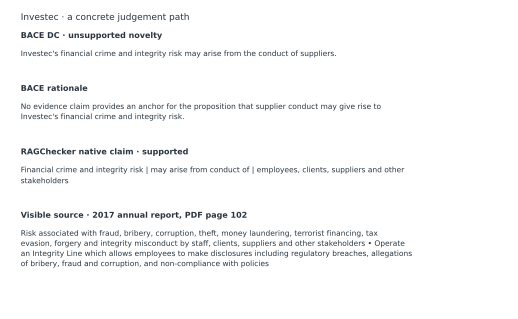

**Read the plate:** native claims and reasons are quoted without semantic rewriting; the source texts come from the same frozen prompt. Full case material is available in the companion case bundle.

[PDF](outputs/figures/03/03_judgement_source_coverage.pdf) · [SVG](outputs/figures/03/03_judgement_source_coverage.svg) · [PNG](outputs/figures/03/03_judgement_source_coverage.png) · [Source data: data](outputs/figures/03/03_judgement_source_coverage__data.csv)

**Pattern and evidence.** The BACE DC concerns suppliers as a source of financial-crime and integrity risk. Its rationale says no EC provides an anchor. RAGChecker’s supported triple includes suppliers among the relevant actors, and the displayed 2017 report text explicitly lists “staff, clients, suppliers and other stakeholders” in the risk definition.

**Interpretation.** The four blocks locate the disagreement in the representation used for judgement: the supplier relation is present in the full visible card even though BACE’s EC-based path reports no anchor. This is a concrete challenge to the absence-of-anchor rationale and helps explain how a low BACE score can coexist with comparator support.

**Limits and alternative readings.** The card predates target year 2021, so this local textual match does not establish every temporal element of the generated claim. The native propositions are related but not a formally adjudicated one-to-one mapping. One inspected disagreement cannot show that RAGChecker is globally more accurate.

<a id="reading-03_judgement_combined_evidence"></a>

**Figure question · 03 judgement combined evidence.** Within the higher-BACE Banco BPM case, why does comparing several cards change the support path?

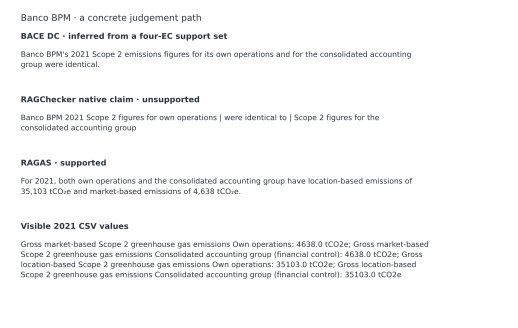

**Read the plate:** native claims and reasons are quoted without semantic rewriting; the source texts come from the same frozen prompt. Full case material is available in the companion case bundle.

[PDF](outputs/figures/03/03_judgement_combined_evidence.pdf) · [SVG](outputs/figures/03/03_judgement_combined_evidence.svg) · [PNG](outputs/figures/03/03_judgement_combined_evidence.png) · [Source data: data](outputs/figures/03/03_judgement_combined_evidence__data.csv)

**Pattern and evidence.** The visible data contain two matching pairs: own-operations and consolidated-group location-based Scope 2 values are each 35,103 tCO₂e, and their market-based values are each 4,638 tCO₂e. BACE accepts the equality statement with one inferred four-EC set; RAGChecker marks its equality claim unsupported after neutral decisions on individual contexts; RAGAS explicitly accepts the cross-value comparison.

**Interpretation.** The equality relation is obtained by comparing records rather than merely repeating one scalar value. The text blocks therefore connect two pairs of equal numbers to different evidence-combination paths. This gives a mechanism for this particular disagreement without assuming that a higher score is preferable.

**Limits and alternative readings.** Matching extracted values establishes equality within these visible records, not independently verified emissions or equivalence of every organisational boundary. The example is deliberately explanatory and cannot measure how frequently each evaluator succeeds at combining evidence.

In [8]:
case_ids={
 'source_coverage':'w2__text_embedding_3_large__stratified_by_evidence_type_n10__investec__2021__g1_4_corruption_bribery_incidents',
 'combined_evidence':'w2__text_embedding_3_large__stratified_by_evidence_type_n10__banco_bpm__2021__e1_6_ghg_emissions'}
for kind,cid in case_ids.items():
    material=case_material(cid)
    if kind=='source_coverage':
        did='dc_ac42ae6401085c4c4b25ea9a5a8a6b3f'
        dc=next(c for c in material['dc'] if c['dc_id']==did)
        diagnosis=next(c for c in material['diagnosis'] if c['dc_claim_id']==did)
        rc=next(c for c in material['ragchecker']['claims'] if 'employees, clients, suppliers and other stakeholders' in ' '.join(c['claim']))
        card=next(c for c in material['input']['prompt_evidence'] if c['prompt_label']=='Evidence 7')
        blocks=[('BACE DC · unsupported novelty',dc['dc_text']),
                ('BACE rationale',diagnosis['rationale']),
                ('RAGChecker native claim · supported',' | '.join(rc['claim'])),
                ('Visible source · 2017 annual report, PDF page 102',card['retrieval_text'])]
        reading='The full visible source explicitly mentions suppliers in the risk definition. BACE judged an extracted EC/candidate representation, while RAGChecker judged card-level contexts. This evidence challenges the absence-of-anchor rationale; it does not establish full 2021 temporal validity or global comparator superiority.'
    else:
        did='dc_63aa1cb575b94ec6692de318547d7e6b'
        dc=next(c for c in material['dc'] if c['dc_id']==did)
        support=next(c for c in material['support'] if c['dc_claim_id']==did)
        assert support['support_sets'][0]['support_type']=='inferred'
        ec_ids=support['support_sets'][0]['ec_claim_ids']
        ecs=[c for c in material['ec'] if c['ec_id'] in ec_ids]
        rc=next(c for c in material['ragchecker']['claims'] if 'were identical to' in c['claim'])
        ra=next(c for c in material['ragas']['claims'] if 'were identical to' in c['claim'])
        evidence_ids={eid for ec in ecs for eid in ec['evidence_card_ids']}
        evidence=[c for c in material['input']['prompt_evidence'] if c['evidence_id'] in evidence_ids]
        values='; '.join(f"{c['metric']}: {c['value_text']} {c['unit'] or ''}" for c in evidence)
        blocks=[('BACE DC · inferred from a four-EC support set',dc['dc_text']),
                ('RAGChecker native claim · unsupported',' | '.join(rc['claim'])),
                ('RAGAS · supported',ra['reason']),('Visible 2021 CSV values',values)]
        reading='The equality statement requires comparing four values across evidence cards. BACE accepted one inferred set containing four ECs; RAGChecker marked every individual context neutral for its equality claim; RAGAS accepted the comparison. This illustrates the role of evidence combination. The underlying CSV values remain extracted data and are not independently verified emissions.'
        assert len(ec_ids)==4 and not rc['supported'] and ra['supported']
    save_json(OUT/'examples'/f'03_{kind}_reading.json',{'case_id':cid,'dc_id':did,'reading':reading,'blocks':blocks})
    quote_figure('03_judgement_'+kind,material['input']['company_name']+' · a concrete judgement path',blocks,
        pd.DataFrame([{'role':a,'text':b} for a,b in blocks]),
        '**Read the plate:** native claims and reasons are quoted without semantic rewriting; the source texts come from the same frozen prompt. Full case material is available in the companion case bundle.')

## What would establish which evaluator is more accurate?

A defensible follow-up requires a shared, independently reviewed target:

1. Audit evidence and disclosure extraction against the complete original visible
   source, including omitted propositions and ambiguous source layouts.
2. Define a shared proposition inventory or an explicitly reviewed mapping that
   represents one-to-many segmentation and reports unmatched content.
3. Have blinded reviewers assess support with all relevant visible evidence,
   preserve sampling probabilities, and adjudicate disagreements.
4. Report evaluator performance against that reference with company-level
   dependence and annotation uncertainty accounted for.

The existing preparation material contains no completed formal human annotations.
A BACE-only DC sample cannot, by itself, fairly benchmark comparator extraction
coverage. Shared model deployment further limits treating agreement as validation.

**Reader checkpoint:** a lower native score means fewer native claims were judged
supported under that pipeline. It does not automatically mean a more accurate,
more useful or more trustworthy evaluator.

## Reproducibility and interpretation boundary

Each figure is exported to `outputs/figures/` as editable PDF/SVG and 600 dpi PNG,
with its plotted source table(s), caption, and rendered QA records. The snapshot
manifest records source hashes and the verification scope. All observations are
retained unless an explicitly named cohort or case-selection rule is stated.

The source checks cover consumed artifacts and their completed-stage receipts,
shared prompt/context/response identity, and native metric arithmetic. They are
not a new audit of every raw model call or the entire extraction lineage.
Read the final audit report for figure-level visual checks and any reviewed warnings.